# L11 — Reinforcement Learning
## The recommender that *learns from clicks*

**Bonus lesson (added by learner request) · hands-on code-along · 80–110 minutes** — ~20 min of key ideas on the slides first, then Parts 1–4 in this notebook (~70 min); Part 5 is optional (~20 min).

> *Sarah Chen · Customer Experience Analyst · NorthStar Retail · a few months after the L10 launch.*
> Sarah's churn model and shopping assistant are live. Now Marcus wants the homepage to **recommend the right product banner to each visitor** — and to *get better on its own* as real shoppers click. Nobody has a labelled "correct banner" list. The system has to learn by trying.
>
> This is a **multi-armed bandit** — named after slot machines ("one-armed bandits"): which machine should you keep playing? It is a simple stateless RL setting: the agent chooses banners and learns from rewards for the actions it took. Having no answer key alone does not make a problem RL; unsupervised learning also lacks labels.

---

### How this session works (why first, then hands-on)

On the slides we first look at **why** NorthStar needs reinforcement learning and the **key ideas** behind it: training a puppy, the NorthStar brief, and the building blocks (agent, environment, state, action, reward, policy) plus the ε dial. This notebook is where you **see those ideas in action** — you build the recommender, look at what it did, then match each key word to the code you just ran.

| Part | What you do | Learning stage |
|---|---|---|
| **0. Why & key ideas** *(slides)* | The business problem, the puppy analogy, the building blocks | Concepts first |
| **1. Do it** | Build an agent that learns which banner gets clicks | Concrete experience |
| **2. Look at it** | Read the learning curve, spot the tension | Reflective observation |
| **3. Connect it** | Match each key word to the code you just ran | Link ideas to experience |
| **4. Tinker** | Change the dials and see what breaks | Active experimentation |
| **5. (Optional) Go deeper** | Add *context* and meet the action-value table | Stretch |

**What you need:** only `numpy` and `matplotlib`. No special RL libraries, no GPU. Run every cell top to bottom.

### Quick recap from the slides: the puppy and the banner agent learn the same way

| | Training a puppy | NorthStar's banner agent |
|---|---|---|
| **The learner** *(agent)* | The puppy | A small program that picks which banner to show |
| **Its world** *(environment)* | You and your home | Visitors arriving on the NorthStar homepage |
| **What it can do** *(action)* | Shake hands, sit, chew the sofa… | Show banner A, B or C |
| **Feedback** *(reward)* | A treat — or "No!" | Click = 1, no click = 0 |
| **Trial and error** | Tries different moves at first | Shows each banner, then shows the winner more often |
| **What it ends up learning** *(policy)* | Which tricks earn treats | Which banner earns the most clicks |

Nobody hands the puppy — or the program — the right answer. Both learn from what happens after they act.

In [1]:
# Run me first. Each experiment creates its own reproducible random generator.
import numpy as np
import matplotlib.pyplot as plt

print("Ready. NorthStar recommender lab is set up.")

Ready. NorthStar recommender lab is set up.


---
# Part 1 — Do it: build a recommender that learns
**⏱ ~25 minutes. Now see the key ideas in action.**

## The situation

NorthStar's homepage can show **one of three product banners** to each visitor:

- **Banner A** — *"New arrivals"*
- **Banner B** — *"Up to 50% off"*
- **Banner C** — *"Trending now"*

When a visitor lands, we pick one banner to show. The visitor either **clicks** (reward = 1) or **doesn't** (reward = 0). That's the only feedback we get. We do **not** know in advance which banner is best — we have to find out by showing them and watching.

Here's the catch that makes this interesting: every time we show a *worse* banner to learn about it, we (probably) lose a click we could have had. So the recommender has to balance **trying things out** against **cashing in on what it already knows.** This is the **explore vs. exploit** trade-off from the slides — watch for it in the results.

In [2]:
# The simulated world is hidden from the agent's decision rule.
true_click_rates = {
    "A · New arrivals": 0.05,
    "B · 50% off": 0.11,
    "C · Trending now": 0.08,
}
banners = list(true_click_rates)
true_rates = np.array(list(true_click_rates.values()))

def validate_world(rates, n_visitors, epsilon=0.0):
    rates = np.asarray(rates, dtype=float)
    if rates.ndim != 1 or rates.size == 0 or not np.all(np.isfinite(rates)):
        raise ValueError("Provide a non-empty, finite, one-dimensional array of rates.")
    if np.any((rates < 0) | (rates > 1)):
        raise ValueError("Click rates must lie between 0 and 1.")
    if not isinstance(n_visitors, (int, np.integer)) or n_visitors <= 0:
        raise ValueError("n_visitors must be a positive integer.")
    if not np.isfinite(epsilon) or not 0 <= epsilon <= 1:
        raise ValueError("epsilon must lie between 0 and 1.")
    return rates

def show_banner(banner_index, rates, rng):
    """Only the environment uses the true rates; the agent receives a 1 or 0."""
    return int(rng.random() < rates[banner_index])

def random_best(values, rng):
    """Break exact ties randomly, so banner order gives no advantage."""
    return int(rng.choice(np.flatnonzero(values == values.max())))

for name, rate in true_click_rates.items():
    print(f"{name:20s} true click rate = {rate:.0%}")
print("\n(The agent's choice rule cannot see these rates — only clicks.)")

A · New arrivals     true click rate = 5%
B · 50% off          true click rate = 11%
C · Trending now     true click rate = 8%

(The agent's choice rule cannot see these rates — only clicks.)


## Approach 1 — the naive baseline: show banners at random

Before anything clever, let's see what happens if the homepage just picks a banner **at random** every time. This is our "do nothing smart" baseline — the number any real method has to beat.

In [3]:
def run_random(n_visitors=5000, rates=None, seed=42):
    rates = validate_world(true_rates if rates is None else rates, n_visitors)
    rng = np.random.default_rng(seed)
    total_clicks = 0
    for _ in range(n_visitors):
        choice = rng.integers(len(rates))
        total_clicks += show_banner(choice, rates, rng)
    return total_clicks

n = 5000
clicks = run_random(n_visitors=n)
print(f"Random banner choice over {n} visitors:")
print(f"  Total clicks: {clicks}")
print(f"  Click rate:   {clicks/n:.2%}")
print(f"  Random policy's expected rate: {true_rates.mean():.2%}")
print(f"  Oracle's expected rate (always choose B): {true_rates.max():.2%}")

Random banner choice over 5000 visitors:
  Total clicks: 385
  Click rate:   7.70%
  Random policy's expected rate: 8.00%
  Oracle's expected rate (always choose B): 11.00%


Random leaves a lot of clicks on the table — it shows the weak banners just as often as the strong one. Now let's build something that **learns.**

## Approach 2 — an agent that learns: ε-greedy ("epsilon-greedy")

The idea in one breath: **mostly show the banner that has performed best so far, but every so often try a random one just to keep learning.**

To do that, the agent keeps a simple scoreboard:

- how many times it has shown each banner, and
- the running **average clicks** (the estimated click rate) for each banner.

Before it starts, the agent shows **each banner once** so every banner has at least one data point — a mini version of the *cold-start burn-in* from the slides. After that, `epsilon` is the one dial that controls how often it explores. `epsilon = 0.1` means: *10% of the time pick a random banner to try; the other 90% show the current best.*

This is the ε-greedy policy from the slides. Here ε stays **fixed at 0.1** for the whole run. Real systems often start with a larger ε and let it shrink over time (*ε decay*) — today we keep it simple so you can see the effect of one setting.

In [4]:
def run_epsilon_greedy(n_visitors=5000, epsilon=0.1, rates=None, seed=42):
    rates = validate_world(true_rates if rates is None else rates, n_visitors, epsilon)
    rng = np.random.default_rng(seed)
    n_actions = len(rates)
    counts = np.zeros(n_actions, dtype=int)
    estimated_rate = np.zeros(n_actions)
    click_history = []

    for t in range(n_visitors):
        if t < n_actions:
            choice = t                                   # warm-up: try every banner once
        elif rng.random() < epsilon:
            choice = rng.integers(n_actions)             # explore any available banner
        else:
            choice = random_best(estimated_rate, rng)    # exploit; randomize ties

        reward = show_banner(choice, rates, rng)
        click_history.append(reward)
        counts[choice] += 1
        estimated_rate[choice] += (reward - estimated_rate[choice]) / counts[choice]

    return counts, estimated_rate, np.array(click_history)

counts, estimated_rate, history = run_epsilon_greedy()
print("After 5000 visitors, the agent estimates:")
for i, name in enumerate(banners):
    print(f"  {name:20s} estimated {estimated_rate[i]:.2%}   (shown {counts[i]} times)")
print(f"\nTotal clicks: {int(history.sum())}  ->  {history.mean():.2%} click rate")
print(f"Random policy's expected rate: {true_rates.mean():.2%}")
print("This is one seeded run; Part 4 compares independent seeds.")

After 5000 visitors, the agent estimates:
  A · New arrivals     estimated 6.02%   (shown 166 times)
  B · 50% off          estimated 10.86%   (shown 4060 times)
  C · Trending now     estimated 8.40%   (shown 774 times)

Total clicks: 516  ->  10.32% click rate
Random policy's expected rate: 8.00%
This is one seeded run; Part 4 compares independent seeds.


Notice two different quantities: **estimated rates** reflect what the agent believes; **times shown** reflect its decisions throughout the run. Neither guarantees it has identified the true best banner. Rarely shown banners have less reliable estimates.

`seed=42` makes this run repeatable. Change the seed to see another possible outcome. Each function call starts a fresh generator, so rerunning earlier cells does not change later experiments.

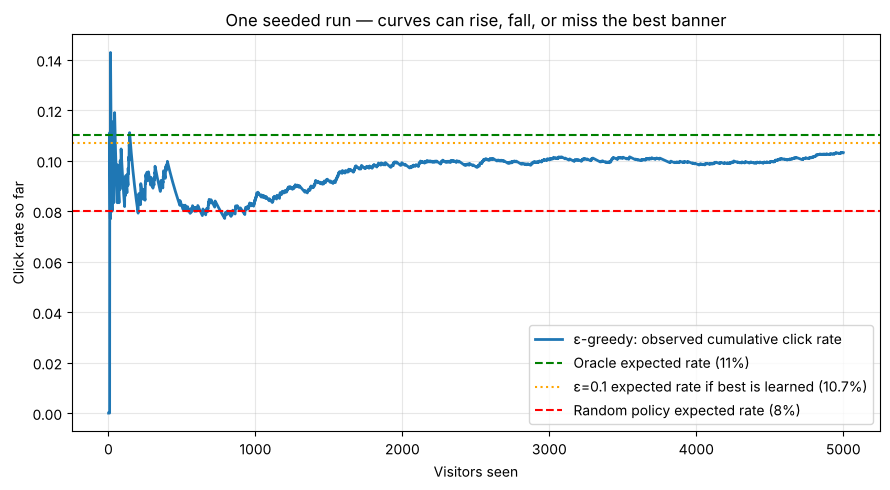

In [5]:
# Cumulative reward is noisy, not a guaranteed rising learning curve.
def running_average(x):
    return np.cumsum(x) / (np.arange(len(x)) + 1)

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(history) + 1), running_average(history),
         label="ε-greedy: observed cumulative click rate", linewidth=2)
plt.axhline(true_rates.max(), color="green", linestyle="--",
            label="Oracle expected rate (11%)")
plt.axhline(0.9 * true_rates.max() + 0.1 * true_rates.mean(), color="orange",
            linestyle=":", label="ε=0.1 expected rate if best is learned (10.7%)")
plt.axhline(true_rates.mean(), color="red", linestyle="--",
            label="Random policy expected rate (8%)")
plt.xlabel("Visitors seen")
plt.ylabel("Click rate so far")
plt.title("One seeded run — curves can rise, fall, or miss the best banner")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This is a **multi-armed bandit**, a simple stateless RL setting: the agent chooses an action and learns from its reward, but today's choice does not change the next visitor. Its running averages guide an ε-greedy policy.

The curve shows cumulative observed clicks, not a direct measure of how much the agent knows. It can fall or stay below random in a finite run. If the agent learns B perfectly, constant ε = 0.1 still spends 10% of choices exploring, giving an expected rate of `0.9 × 11% + 0.1 × 8% = 10.7%`. The 11% line is the oracle's expected rate, not a cap on random observed results. Part 4 checks variability across independent runs.

---
# Part 2 — Look at it: what just happened?
**⏱ ~10 minutes. Reflect on what you saw.**

Answer these for yourself (jot a sentence each), *then* run the cell to compare with Sarah's take.

1. Why did the agent show banner B so much more than A or C?
2. What would happen if `epsilon = 0` (never explore)? Could the agent get *stuck* on a banner that just got lucky early?
3. The agent never knew the true click rates. So what exactly did it "learn"?

In [6]:
print("""Sarah's reflection
------------------
1. Exploit steps favor the banner with the highest estimated rate at that time.
   Traffic counts summarize past choices, not necessarily the final best estimate.

2. With epsilon = 0, a weak banner's early click can make it the only positive
   estimate. Unvisited alternatives then get no new evidence. All-zero ties are
   common at these low click rates; our code breaks them randomly, rather than
   always favoring A. Positive epsilon keeps every banner eligible for trials,
   but does not guarantee the right answer within 5000 visitors.

3. The agent estimates rewards and uses them to improve its policy. Rewards
   only describe the action taken, not what the other banners would have earned.
""")

Sarah's reflection
------------------
1. Exploit steps favor the banner with the highest estimated rate at that time.
   Traffic counts summarize past choices, not necessarily the final best estimate.

2. With epsilon = 0, a weak banner's early click can make it the only positive
   estimate. Unvisited alternatives then get no new evidence. All-zero ties are
   common at these low click rates; our code breaks them randomly, rather than
   always favoring A. Positive epsilon keeps every banner eligible for trials,
   but does not guarantee the right answer within 5000 visitors.

3. The agent estimates rewards and uses them to improve its policy. Rewards
   only describe the action taken, not what the other banners would have earned.



---
# Part 3 — Connect it: match the key words to your code
**⏱ ~20 minutes. You met these words on the slides — now find each one in the code you just ran.**

## The core loop

Every reinforcement learning system is the same loop, repeated thousands of times:

> An **agent** looks at its situation, takes an **action**, gets a **reward**, and **updates** how it will act next time.

That's it. Games, robots, self-driving cars, and language-model policy training share this broad pattern. Here is the vocabulary, each term tied to your banner code:

| Term | Plain English | In your code |
|---|---|---|
| **Agent** | The learner / decision-maker | Your `run_epsilon_greedy` function |
| **Environment** | The world it acts on | NorthStar's visitors (`show_banner`) |
| **State** | What the agent sees before it chooses | Nothing yet — every visitor looks the same (Part 5 adds visitor type) |
| **Action** | A choice the agent can make | Which banner to show (A / B / C) |
| **Reward** | The feedback signal — bigger = better | `1` for a click, `0` for none |
| **Policy** | The agent's *strategy* for choosing actions | "90% show best, 10% explore" |
| **Value estimate** | The agent's belief about how good each action is | `estimated_rate` per banner |

**Real-world analogy — choosing a lunch spot.** You're new to an area with three cafés. Each visit is an *action*; how much you enjoy lunch is the *reward*. Go only to the first decent one you find and you might miss a better café next door (*no exploration*). Try a new place at random every single day and you waste good lunches on bad cafés (*too much exploration*). Sensible people mostly return to their favourite but occasionally try somewhere new. That sensible habit is a **policy**, and that's exactly what ε-greedy automates.

## A central tension: explore vs. exploit

This is the idea worth remembering long after today:

- **Exploit** = use what you already know to get reward *now* (show the best-known banner).
- **Explore** = try an action to gain information, potentially sacrificing immediate reward.

Exploring can also earn reward. The question is how to balance immediate reward with information:

- **Too little exploration** → you can lock onto a mediocre choice and miss a better one (the `epsilon = 0` trap from Part 2).
- **Too much exploration** → you keep gambling on weak options and bleed reward.

`epsilon` is literally the knob for this trade-off. That's why this tiny algorithm is a genuine RL method, not a toy.

## How is this different from supervised learning?

| | Supervised learning | Reinforcement learning |
|---|---|---|
| **What it's given** | A dataset of inputs *with correct answers* | Rewards for actions taken, without observing alternative outcomes |
| **Feedback** | "The right label was X" | "That choice earned 1" (never told the *best* choice) |
| **What feedback describes** | Targets for the observed training examples | Rewards for actions taken; alternative outcomes are unobserved |
| **Sarah example** | Classify a review as positive/negative | Learn which banner earns clicks |

In this demo, the agent chooses which data to collect and uses action-specific rewards to improve its policy. Supervised learning can also run online, and RL can learn offline from logged experience. The learning objective and feedback structure matter more than when data arrives. That's why there's no training CSV here — the data is *generated by the agent's own choices.*

> **Key takeaway.** Reinforcement learning = learning a *policy* (a habit of acting) from *rewards* (feedback on actions), while balancing *exploration* against *exploitation*. Full RL also requires reasoning about state transitions and long-term returns.

**Changing tastes:** this demo assumes fixed click probabilities. Its lifetime averages adapt slowly after lots of traffic. For a changing world, use recency-weighted updates or a sliding window and evaluate that behavior separately.


---
# Part 4 — Tinker: turn the dials
**⏱ ~15 minutes. Experiment — this is where intuition sticks.**

Run the experiments below and watch how behaviour changes. Predict the result *before* you run each one.

In [7]:
# Experiment A: independent runs, with reproducible seeds for each epsilon.
# Standard deviation describes run-to-run variability, not a confidence interval.
for eps in [0.0, 0.01, 0.1, 0.5, 1.0]:
    rates_observed, best_identified = [], []
    for seed in range(20):
        _, est, h = run_epsilon_greedy(epsilon=eps, seed=seed)
        rates_observed.append(h.mean())
        leaders = np.flatnonzero(est == est.max())
        best_identified.append(len(leaders) == 1 and leaders[0] == np.argmax(true_rates))
    print(f"epsilon={eps:<4}  mean={np.mean(rates_observed):.2%}, "
          f"SD={np.std(rates_observed, ddof=1):.2%}; "
          f"unique best estimate is B: {np.mean(best_identified):.0%} of runs")
print("\nAt epsilon=1, all choices after warm-up are random, even if estimates rank B first.")
print("The strongest epsilon depends on the rates, horizon, initialization, and seed.")

epsilon=0.0   mean=8.98%, SD=2.31%; unique best estimate is B: 50% of runs


epsilon=0.01  mean=10.02%, SD=1.34%; unique best estimate is B: 80% of runs


epsilon=0.1   mean=10.48%, SD=0.59%; unique best estimate is B: 100% of runs


epsilon=0.5   mean=9.51%, SD=0.49%; unique best estimate is B: 100% of runs


epsilon=1.0   mean=7.94%, SD=0.55%; unique best estimate is B: 100% of runs

At epsilon=1, all choices after warm-up are random, even if estimates rank B first.
The strongest epsilon depends on the rates, horizon, initialization, and seed.


Compare **reward earned** with **best banner identified**: they answer different questions. A policy can identify B late after losing many clicks early. At ε = 1, it can estimate B correctly without exploiting that knowledge at all.

The reported standard deviation shows how much the realized rate varies across 20 independent seeds. It is not a confidence interval. There is no universal best epsilon: try changing the visitor budget and rates. Repeating the same seed reproduces the same outcome; use another seed for a new trial.

In [8]:
# Experiment B: customize the world without changing global state.
# Make C strongest, make rates nearly equal, or add D to BOTH lists.
your_banners = ["A · New arrivals", "B · 50% off", "C · Trending now", "D · Members"]
your_rates = np.array([0.05, 0.11, 0.08, 0.15])
if len(your_banners) != len(your_rates):
    raise ValueError("Provide one banner name per click rate.")

counts, est, hist = run_epsilon_greedy(rates=your_rates, seed=42)
leaders = np.flatnonzero(est == est.max())
print(f"World: {dict(zip(your_banners, your_rates))}")
print("Highest estimated rate: " + ", ".join(your_banners[i] for i in leaders))
print(f"Observed click rate: {hist.mean():.2%}")
print("True best: " + ", ".join(your_banners[i] for i in np.flatnonzero(your_rates == your_rates.max())))
print(f"Times shown: {counts.tolist()}")
print("Change seed for another independent trial; the best banner is not guaranteed.")

World: {'A · New arrivals': np.float64(0.05), 'B · 50% off': np.float64(0.11), 'C · Trending now': np.float64(0.08), 'D · Members': np.float64(0.15)}
Highest estimated rate: D · Members
Observed click rate: 14.58%
True best: D · Members
Times shown: [117, 143, 158, 4582]
Change seed for another independent trial; the best banner is not guaranteed.


---
# Part 5 — (Optional) Go deeper: add *context* and meet the action-value table
**⏱ ~20 minutes. Stretch material — skip if you're full.**

So far the agent showed the *same* best banner to everyone. But a first-time visitor and a loyal member probably respond to different banners. Real recommenders use **context** — something they know about the situation *before* choosing. In the language of the slides, the visitor type is now a simple **state**.

This upgrade has a name: a **contextual bandit**, and it's a half-step toward full reinforcement learning. The new idea is a **contextual-bandit action-value table**, sometimes called a Q-table: instead of one score per action, the agent keeps *a score per action for each kind of situation.* Here `Q` estimates immediate click probability. This is not Q-learning: there is no next-state value or Bellman update.

NorthStar knows one thing about each visitor: are they a **new** visitor or a **returning** member? Run the agent and check whether it identifies the different best banners.

In [9]:
true_rates_by_type = np.array([
    [0.04, 0.12, 0.06],   # new visitors: B best
    [0.10, 0.05, 0.13],   # returning visitors: C best
])
visitor_types = ["new", "returning"]

def run_contextual(n_visitors=8000, epsilon=0.1, seed=42):
    n_types, n_actions = true_rates_by_type.shape
    for row in true_rates_by_type:
        validate_world(row, n_visitors, epsilon)
    rng = np.random.default_rng(seed)
    Q = np.zeros((n_types, n_actions))
    counts = np.zeros_like(Q, dtype=int)
    for _ in range(n_visitors):
        vtype = rng.integers(n_types)
        untried = np.flatnonzero(counts[vtype] == 0)
        if len(untried):
            choice = int(rng.choice(untried))
        elif rng.random() < epsilon:
            choice = rng.integers(n_actions)
        else:
            choice = random_best(Q[vtype], rng)
        reward = show_banner(choice, true_rates_by_type[vtype], rng)
        counts[vtype, choice] += 1
        Q[vtype, choice] += (reward - Q[vtype, choice]) / counts[vtype, choice]
    return Q

Q = run_contextual()
print("Contextual-bandit action-value table (estimated click rates):\n")
for t, visitor_type in enumerate(visitor_types):
    leaders = np.flatnonzero(Q[t] == Q[t].max())
    names = ", ".join(banners[i] for i in leaders)
    print(f"  {visitor_type:12s} {Q[t].round(4)}  -> highest estimate: {names}")
print("\nThese are immediate-reward sample averages, not a Q-learning update.")
print("Different seeds can identify different winners; estimates are uncertain.")

Contextual-bandit action-value table (estimated click rates):

  new          [0.034  0.1229 0.0571]  -> highest estimate: B · 50% off
  returning    [0.127  0.0301 0.1381]  -> highest estimate: C · Trending now

These are immediate-reward sample averages, not a Q-learning update.
Different seeds can identify different winners; estimates are uncertain.


### Where this leads (the one-paragraph map of full RL)

A contextual bandit chooses based on the *current* situation, but each choice is independent — showing a banner now doesn't change the *next* visitor. **Full reinforcement learning** adds one more idea: your action changes the *state* of the world, so you must think about **long-term** reward, not just the next click. A chess move, a robot step, or a multi-step checkout flow all work this way — a small sacrifice now can win later. The full-RL toolkit (Q-learning over states, policy gradients, deep RL) is just this same explore/learn/act loop scaled up to handle *sequences* of decisions. Notably, it's also how modern chatbots are tuned: **RLHF — reinforcement learning from human feedback** — asks people which of two answers they prefer, trains a *reward model* to predict those preferences, and then uses that reward to update the model's policy — the same act → reward → update loop you built in Part 1, at a vastly larger scale.

You don't need that machinery today. You have built a small example of the action → reward → update pattern; sequential RL needs additional methods for long-term returns.

---
## ✅ Session summary

| You learned | In one line |
|---|---|
| **The RL loop** | Agent → action → reward → update, repeated |
| **The key words** | agent, environment, state, action, reward, policy, value |
| **Explore vs exploit** | Trade reward-now against learning-for-later; `epsilon` is the dial |
| **RL vs supervised** | Choose actions and improve a policy using their rewards |
| **Contextual bandit** | Estimate immediate reward per action and context; this table is not yet Q-learning |
| **Where it scales** | Sequences of decisions → full RL → RLHF behind modern chatbots |

**The mindset shift to keep:** supervised learning answers *"what is this?"* from labelled examples; reinforcement learning answers *"what should I do?"* from the consequences of trying. NorthStar's banner picker introduces this pattern without state transitions or delayed rewards.

> *"We never told it which banner was best. We let it collect click feedback and checked what it learned. Changing tastes would need another experiment."* — Sarah, after the homepage relaunch.